In [21]:
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt
import seaborn as sns

from TrailPredictor.loading import load_activities

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
activities = load_activities()
print(activities.shape)
activities.head(3)

(1666, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
0,20698713759,"23 oct. 2026, 10:09:01",Entraînement aux poids le midi,weight_training,NaN,1596.0,0.00,157.0,5.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,142.0,NaN
1,20678393964,"21 oct. 2026, 16:43:26",[🏃‍♂️🏃‍♀️🏃🏼‍♀️ Blabla run avec katia et Marie 🌃],run,69 charge d'entraînement\n-- de COROS,5038.0,12.71,158.0,24.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,|
2,20673608797,"21 oct. 2026, 10:53:06",[🏋️ Pause renfo 💪],weight_training,NaN,2723.0,0.00,114.0,5.0,False,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,18.0,162.0,NaN


<Axes: xlabel='type', ylabel='count'>

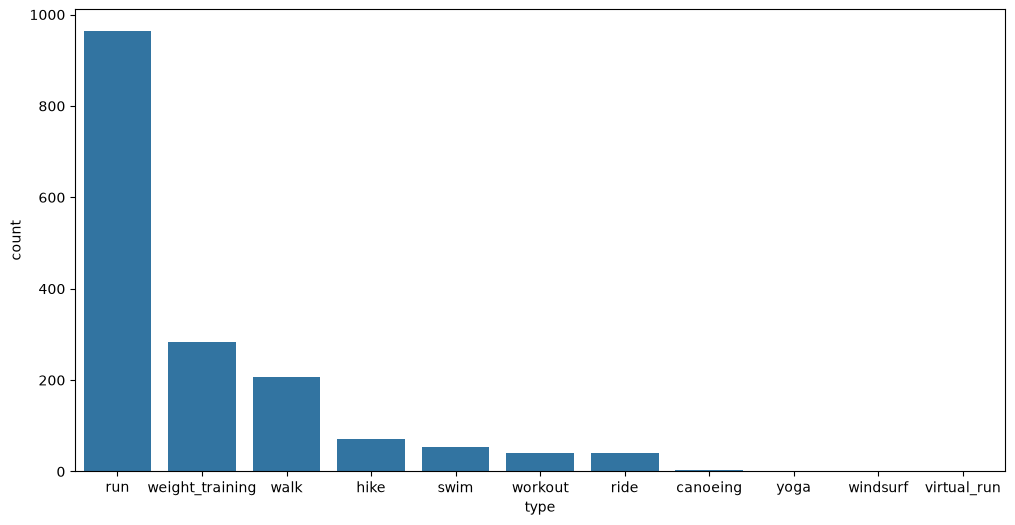

In [23]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=activities["type"].value_counts().reset_index(), x="type", y="count", ax=ax
)

In [24]:
act = activities[activities["type"] == "run"].sort_values(
    "distance_km", ascending=False
)
print(act.shape)
file_path = act[act["id"] == 11807872158].iloc[0]["file_name"]
act.head(5)

(963, 102)


,id,date,name,type,description,elapsed_time,distance_km,max_heart_rate,relative_effort,is_commute,...,is_recovery,with_pet,is_race,is_long_run,is_charity,with_child,downhill_distance,total_sets,total_reps,support
683,13026008640,"30 nov. 2024, 23:11:13",[🏃 🏃🏼‍♀️ Saintélyon 🌜🌞],run,Une saintélyon en binôme avec [strava://athlet...,43813.0,82.36,179.0,577.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9564868f-742d-4b17-8c78-7fec7294c7bd.jpg...
908,10975302024,"16 mars 2024, 10:36:08",[🗼80k - Ecotrail de Paris 🎂],run,🎉Premier 80km pour mes 27ans 🎂 🎊\r\n\r\nPremie...,33706.0,81.87,187.0,1085.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f0e27ecf-caec-4e13-9ba7-d9357e9db464.jpg...
842,11682866712,"15 juin 2024, 07:30:40",[ 🐚 100k Saint-Jacques ],run,J'ai pris ma revanche sur le Saint-Jacques by ...,41920.0,81.01,183.0,1012.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/9d9e4ea3-9dec-477f-a79e-568d549b0aa8.jpg...
193,17807912509,"21 mars 2026, 09:42:34",[🗼80k - Ecotrail de Paris 🎂],run,J'ai réussi à obtenir un dossard il y a une se...,38540.0,80.68,179.0,790.0,False,...,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,media/70e2f4f3-1a41-4374-a31f-33b248575d8b.jpg...
831,11807872158,"4 juil. 2024, 05:30:04",[ 🇪🇸 PDA - Val D'Aran byUTMB 🗻 ],run,Très content d'avoir pu m'aligner sur la ligne...,32759.0,51.39,188.0,868.0,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,media/f2d3536c-3f32-4fdd-af8a-9bb4f5abcf66.jpg...


In [25]:
from TrailPredictor import RunningActivities

segment_width = 100
race = RunningActivities.from_computed_file(file_path, segment_width)
race.name = "test"
race.data.head(4)

,segment,elapsed_time,timestamp,distance,heart_rate,altitude,position_lat,position_long,drop_pos,drop_neg,speed,log_speed,pace,log_pace,accel_speed,log_accel_speed,accel_pace,log_accel_pace,name
0,0,0 days 00:00:40,2024-07-04 05:30:04+00:00,100.0,101.675000,1258.750000,42.707340,0.902902,5.0,-2.0,2.500000,0.916291,6.666667,1.897120,NaN,NaN,NaN,NaN,test
1,1,0 days 00:00:33,2024-07-04 05:30:44+00:00,200.0,143.545455,1259.030303,42.707107,0.901687,1.0,-8.0,3.030303,1.108663,5.500000,1.704748,0.530303,-0.634307,0.962500,-0.038221,test
2,2,0 days 00:00:30,2024-07-04 05:31:17+00:00,300.0,156.800000,1252.466667,42.707086,0.900635,0.0,-7.0,3.333333,1.203973,5.000000,1.609438,0.303030,-1.193922,0.454545,-0.788457,test
3,3,0 days 00:00:34,2024-07-04 05:31:47+00:00,400.0,152.911765,1248.588235,42.706651,0.900157,3.0,-2.0,2.941176,1.078810,5.666667,1.734601,-0.392157,NaN,-0.755556,NaN,test


In [26]:
race.plot.pace_by_segment().show()
# race.plot.hr_overlay().show()
race.plot.track_map().show()
# race.plot.altitude().show()
# race.plot.speed().show()
# race.plot.time_in_hr_zones()

In [27]:
from TrailPredictor.plot import plot_minetti_curve

plot_minetti_curve()

In [28]:
from TrailPredictor.dataset import Dataset

dataset = Dataset.load(min_distance=40, max_distance=100, segment_width=500)
plotter = dataset.plot

In [29]:
# plotter.merge_figure(plotter.target_histogram, title="Histogram of target ")
# plotter.merge_figure(
#     plotter.target_vs_feat, title="Target vs Altitude Drop", features="altitude_drop"
# ).show()
# plotter.merge_figure(
#     plotter.target_vs_feat,
#     title="Target vs Altitude Drop (Positive)",
#     features="altitude_drop_pos",
# )

In [30]:
# dataset.features = [
#     "altitude_drop_pos",
#     "altitude_drop_neg_done",
#     "altitude_drop_pos_done",
#     "altitude_drop_pos_total",
#     "altitude_drop_pos_back_3km",
#     "altitude_drop_neg_back_10km",
#     # "running_cost",
#     # "walking_cost",
#     # "slope",
# ]

In [31]:
dataset.target = "pace"
N_SPLITS = min(5, dataset.data["activity_id"].nunique())
RANDOM_STATE = 42
y = dataset.target
X = dataset.predictors
groups = dataset.data["activity_id"]